# Vision Transformer (ViT) — Plant Disease Detection Experiment
**Paper:** Plant disease detection using vision transformers  
**Framework:** PyTorch  
**Dataset:** dataset_smartcrop_new (pre-split train/val/test)

| Scenario | Augmentation |
|----------|--------------|
| Baseline | None (Resize 256×256 + Normalize) |
| Augmented | HFlip + Crop + Contrast + GaussNoise + Brightness + Affine |

In [1]:
# BLOCK 0: Install
!pip install -q torchinfo openpyxl Pillow

In [ ]:
# BLOCK 1: Imports
import os, math, numpy as np, matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchinfo import summary as torch_summary
from PIL import Image
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
n_gpus = torch.cuda.device_count()
print(f'Device: {DEVICE} | GPUs available: {n_gpus}')

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
print('Seed=42 | cudnn.deterministic=True | benchmark=False')

In [4]:
# BLOCK 2: Config
DATASET_DIR    = '/kaggle/input/datasets/tminhhi/finaldata/dataset_smartcrop_new'
TRAIN_DIR      = os.path.join(DATASET_DIR, 'train')
VAL_DIR        = os.path.join(DATASET_DIR, 'val')
TEST_DIR       = os.path.join(DATASET_DIR, 'test')
OUTPUT_DIR     = '/kaggle/working'
PAPER_CITATION = 'Plant disease detection using vision transformers'
MODEL_NAME     = 'ViT'

IMG_SIZE    = (256, 256)
PATCH_SIZE  = 16
EMBED_DIM   = 512
NUM_HEADS   = 8
NUM_LAYERS  = 4
FFN_DIM     = 2048
BATCH_SIZE  = 32
EPOCHS      = 20
LR          = 1e-4

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
# BLOCK 3: Dataset Exploration
CLASS_NAMES = sorted(os.listdir(TRAIN_DIR))
NUM_CLASSES = len(CLASS_NAMES)
print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')

def count_images(root):
    counts = {}
    for cls in CLASS_NAMES:
        cls_dir = os.path.join(root, cls)
        if os.path.isdir(cls_dir):
            counts[cls] = len([f for f in os.listdir(cls_dir)
                               if f.lower().endswith(('.jpg','.jpeg','.png'))])
        else:
            counts[cls] = 0
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)
test_counts  = count_images(TEST_DIR)

print(f'Train total: {sum(train_counts.values())} | Val: {sum(val_counts.values())} | Test: {sum(test_counts.values())}')

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, counts, title in zip(axes,
                              [train_counts, val_counts, test_counts],
                              ['Train', 'Validation', 'Test']):
    ax.bar(range(len(CLASS_NAMES)), [counts[c] for c in CLASS_NAMES])
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_title(f'{title} Set', fontsize=13, fontweight='bold')
    ax.set_ylabel('Images')
plt.suptitle('Dataset Statistics', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/dataset_statistics.png', dpi=300, bbox_inches='tight')
plt.show()

# Class imbalance auto-detection (Rule 11)
train_counts_arr = np.array([train_counts[c] for c in CLASS_NAMES])
max_count = int(train_counts_arr.max())
min_count = int(train_counts_arr.min())
imbalance_ratio = max_count / min_count
print(f'Class imbalance ratio (max/min): {imbalance_ratio:.2f}')
if imbalance_ratio >= 1.5:
    from sklearn.utils.class_weight import compute_class_weight
    all_labels = []
    for cls_idx, cls in enumerate(CLASS_NAMES):
        all_labels.extend([cls_idx] * train_counts[cls])
    CLASS_WEIGHTS = compute_class_weight(
        'balanced', classes=np.arange(NUM_CLASSES), y=np.array(all_labels)
    )
    CLASS_WEIGHTS_TENSOR = torch.tensor(CLASS_WEIGHTS, dtype=torch.float32)
    print(f'[Class Weighting] ENABLED — ratio={imbalance_ratio:.2f} >= 1.5')
    print(f'  weights: {CLASS_WEIGHTS.round(3)}')
else:
    CLASS_WEIGHTS_TENSOR = None
    print(f'[Class Weighting] DISABLED — balanced (ratio={imbalance_ratio:.2f} < 1.5)')

In [6]:
# BLOCK 4: Dataset Class
class PlantDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.transform = transform
        self.samples = []
        self.class_to_idx = {cls: i for i, cls in enumerate(CLASS_NAMES)}
        for cls in CLASS_NAMES:
            cls_dir = os.path.join(root_dir, cls)
            if not os.path.isdir(cls_dir):
                continue
            for fname in os.listdir(cls_dir):
                if fname.lower().endswith(('.jpg','.jpeg','.png')):
                    self.samples.append((os.path.join(cls_dir, fname),
                                        self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

In [ ]:
# BLOCK 5: ViT Architecture (from scratch)

class PatchEmbedding(nn.Module):
    def __init__(self, img_size, patch_size, in_channels, embed_dim):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim,
                              kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)       # (B, embed_dim, H/P, W/P)
        x = x.flatten(2)       # (B, embed_dim, num_patches)
        x = x.transpose(1, 2) # (B, num_patches, embed_dim)
        return x


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, ffn_dim):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn  = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn   = nn.Sequential(
            nn.Linear(embed_dim, ffn_dim),
            nn.GELU(),
            nn.Linear(ffn_dim, embed_dim),
        )

    def forward(self, x):
        normed = self.norm1(x)
        attn_out, _ = self.attn(normed, normed, normed)
        x = x + attn_out
        x = x + self.ffn(self.norm2(x))
        return x


class ViT(nn.Module):
    def __init__(self, img_size, patch_size, in_channels, embed_dim,
                 num_heads, num_layers, ffn_dim, num_classes):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = (img_size // patch_size) ** 2
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches, embed_dim) * 0.02)
        self.encoder   = nn.Sequential(
            *[TransformerEncoderBlock(embed_dim, num_heads, ffn_dim)
              for _ in range(num_layers)]
        )
        flat_dim = num_patches * embed_dim  # 256 * 512 = 131072
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 256), nn.ReLU(),
            nn.Linear(256, 2048),     nn.ReLU(),
            nn.Linear(2048, 1024),    nn.ReLU(),
            nn.Linear(1024, 512),     nn.ReLU(),
            nn.Linear(512, 256),      nn.ReLU(),
            nn.Linear(256, 128),      nn.ReLU(),
            nn.Linear(128, 64),       nn.ReLU(),
            nn.Linear(64, 32),        nn.ReLU(),
            nn.Linear(32, num_classes),
        )

    def forward(self, x):
        x = self.patch_embed(x) + self.pos_embed
        x = self.encoder(x)
        return self.head(x)


def build_model():
    model = ViT(
        img_size=IMG_SIZE[0], patch_size=PATCH_SIZE,
        in_channels=3, embed_dim=EMBED_DIM,
        num_heads=NUM_HEADS, num_layers=NUM_LAYERS,
        ffn_dim=FFN_DIM, num_classes=NUM_CLASSES
    ).to(DEVICE)
    if n_gpus > 1:
        model = nn.DataParallel(model)
        print(f'[Multi-GPU] DataParallel on {n_gpus} GPUs')
    return model


# Print model summary (dùng .module khi DataParallel — Rule 14)
_tmp = build_model()
_m = _tmp.module if isinstance(_tmp, nn.DataParallel) else _tmp
torch_summary(_m, input_size=(1, 3, *IMG_SIZE),
              col_names=['output_size', 'num_params', 'trainable'])
del _tmp

In [ ]:
# BLOCK 6: Evaluation & Artifact Functions

def evaluate(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            preds = model(imgs).argmax(dim=1).cpu().numpy()
            y_pred.extend(preds)
            y_true.extend(labels.numpy())
    return np.array(y_true), np.array(y_pred)


def load_best_model(model, checkpoint_path):
    _target = model.module if isinstance(model, nn.DataParallel) else model
    _target.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    print(f'[Checkpoint] Loaded best weights from {checkpoint_path}')
    return model


def train_model(model, train_loader, val_loader, epochs, checkpoint_path,
                class_weights_tensor=None):
    weight    = class_weights_tensor.to(DEVICE) if class_weights_tensor is not None else None
    criterion = nn.CrossEntropyLoss(weight=weight)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    history   = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            out  = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
            correct      += (out.argmax(1) == labels).sum().item()
            total        += imgs.size(0)

        train_loss = running_loss / total
        train_acc  = correct / total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                out  = model(imgs)
                loss = criterion(out, labels)
                val_loss    += loss.item() * imgs.size(0)
                val_correct += (out.argmax(1) == labels).sum().item()
                val_total   += imgs.size(0)

        val_loss /= val_total
        val_acc   = val_correct / val_total

        star = ''
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            _state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
            torch.save(_state, checkpoint_path)
            star = ' ★ saved'

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        print(f'Epoch {epoch:02d}/{epochs} | '
              f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}{star}')

    print(f'Best val_acc: {best_val_acc:.4f} → {checkpoint_path}')
    return history


def save_learning_curve(history, title, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history['train_acc'], label='Train')
    axes[0].plot(history['val_acc'],   label='Val')
    axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(True)

    axes[1].plot(history['train_loss'], label='Train')
    axes[1].plot(history['val_loss'],   label='Val')
    axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True)

    plt.suptitle(title, fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


def save_confusion_matrix(y_true, y_pred, title, save_path):
    cm   = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(14, 12))
    disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, colorbar=True)
    ax.set_title(title, fontsize=16, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=14)
    ax.set_ylabel('True Label', fontsize=14)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

---
## SCENARIO 1: NO AUGMENTATION (BASELINE)

In [ ]:
# BLOCK 7: Transforms — Scenario 1 (No-Aug)
transform_noaug = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_ds_1 = PlantDataset(TRAIN_DIR, transform=transform_noaug)
val_ds_1   = PlantDataset(VAL_DIR,   transform=transform_noaug)
test_ds_1  = PlantDataset(TEST_DIR,  transform=transform_noaug)

train_loader_1 = DataLoader(train_ds_1, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader_1   = DataLoader(val_ds_1,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader_1  = DataLoader(test_ds_1,  batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f'Train: {len(train_ds_1)} | Val: {len(val_ds_1)} | Test: {len(test_ds_1)}')

In [ ]:
# BLOCK 8: Train — Scenario 1
CKPT_S1   = f'{OUTPUT_DIR}/best_model_s1.pth'
model_1   = build_model()
history_1 = train_model(model_1, train_loader_1, val_loader_1, EPOCHS, CKPT_S1, CLASS_WEIGHTS_TENSOR)
model_1   = load_best_model(model_1, CKPT_S1)  # reload best before evaluate

In [11]:
# BLOCK 9: Classification Report — Scenario 1
y_true_1, y_pred_1 = evaluate(model_1, test_loader_1)

acc_1    = accuracy_score(y_true_1, y_pred_1)
f1_1     = f1_score(y_true_1, y_pred_1, average='macro', zero_division=0)
recall_1 = recall_score(y_true_1, y_pred_1, average='macro', zero_division=0)
params_1 = sum(p.numel() for p in model_1.parameters())

print(f'[Scenario 1 — No-Aug]')
print(f'  Total Parameters : {params_1:,}')
print(f'  Accuracy         : {acc_1:.4f}')
print(f'  F1-Score (Macro) : {f1_1:.4f}')
print(f'  Recall (Macro)   : {recall_1:.4f}')
print()
print(classification_report(y_true_1, y_pred_1, target_names=CLASS_NAMES, digits=4))

BASELINE_LEARNING_CURVE_PATH   = f'{OUTPUT_DIR}/{MODEL_NAME}_NoAug_LC.png'
BASELINE_CONFUSION_MATRIX_PATH = f'{OUTPUT_DIR}/{MODEL_NAME}_NoAug_CM.png'
baseline_metrics = {
    'model_name'   : MODEL_NAME,
    'accuracy'     : acc_1,
    'f1_macro'     : f1_1,
    'recall_macro' : recall_1,
    'total_params' : params_1,
}

[Scenario 1 — No-Aug]
  Total Parameters : 50,013,061
  Accuracy         : 0.6917
  F1-Score (Macro) : 0.7084
  Recall (Macro)   : 0.7032

                     precision    recall  f1-score   support

        anthracnose     1.0000    1.0000    1.0000        62
            healthy     0.6765    0.5897    0.6301        78
          leaf_curl     0.5926    0.6486    0.6194        74
          leaf_spot     0.4536    0.5789    0.5087        76
nutrient_deficiency     0.8923    0.6988    0.7838        83

           accuracy                         0.6917       373
          macro avg     0.7230    0.7032    0.7084       373
       weighted avg     0.7162    0.6917    0.6989       373



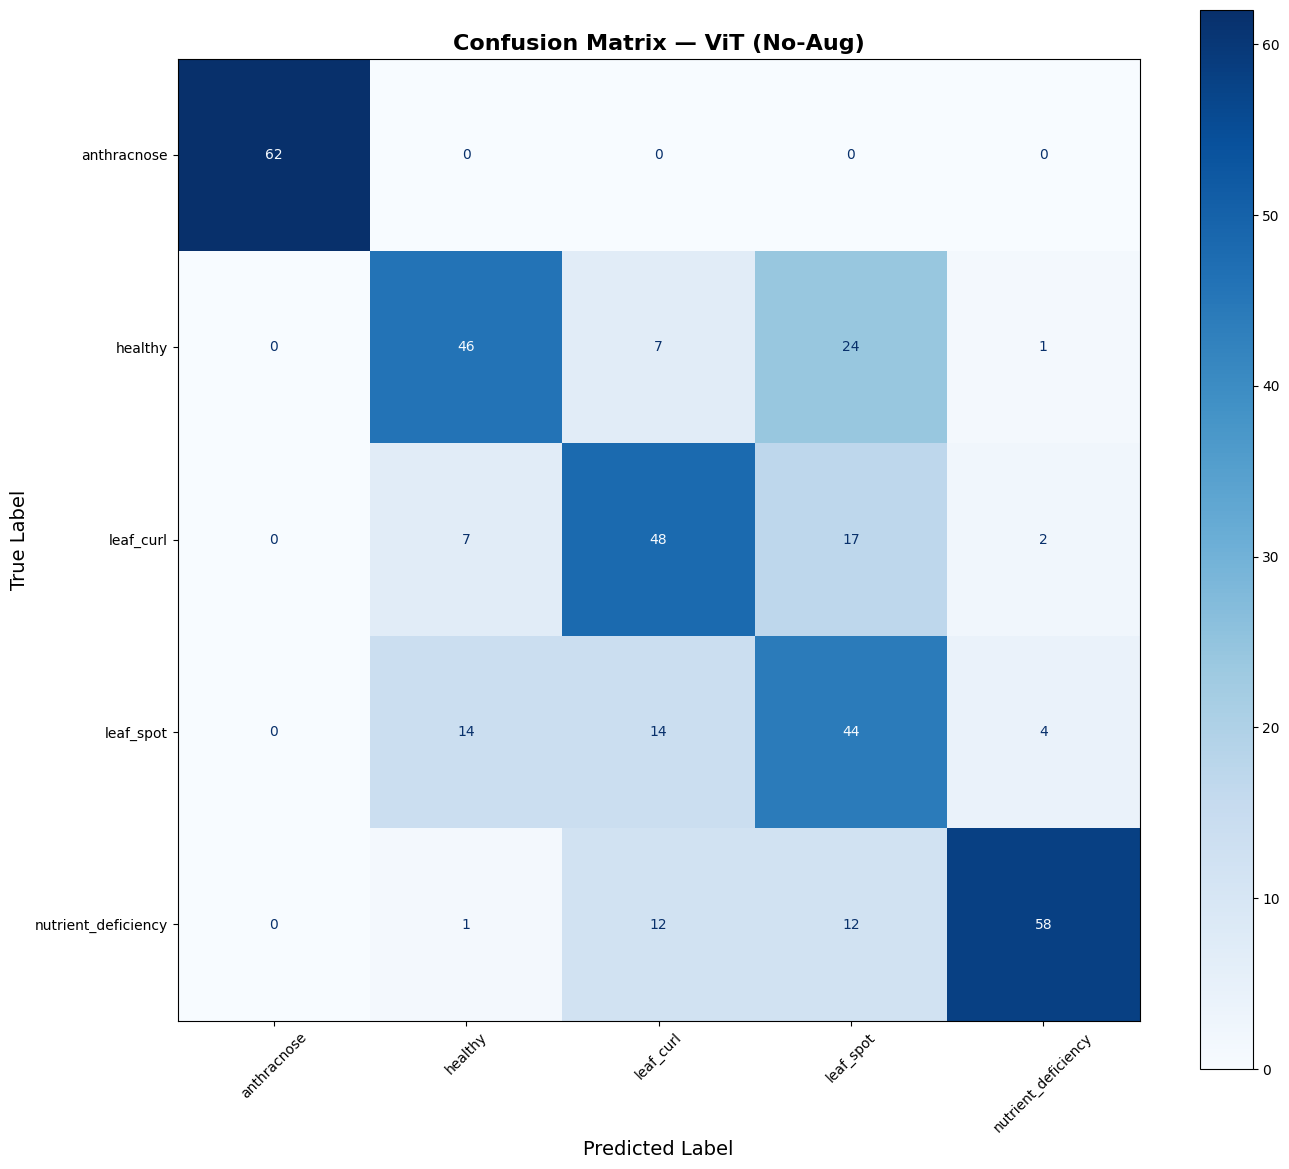

In [12]:
# BLOCK 10: Confusion Matrix — Scenario 1 (CELL RIÊNG BIỆT)
save_confusion_matrix(
    y_true_1, y_pred_1,
    title=f'Confusion Matrix — {MODEL_NAME} (No-Aug)',
    save_path=BASELINE_CONFUSION_MATRIX_PATH
)

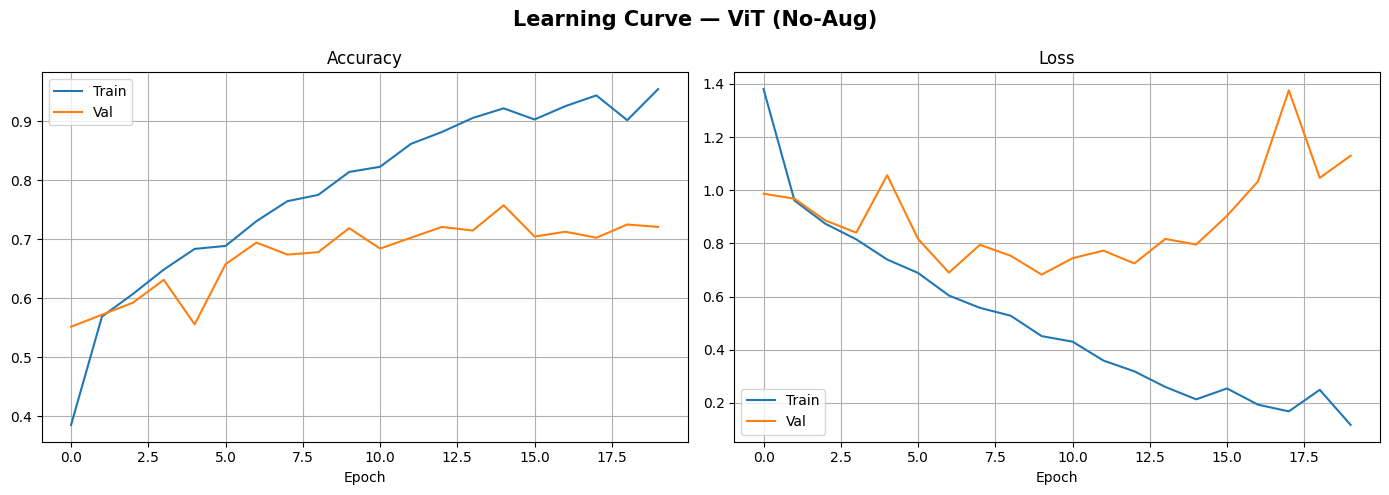

In [13]:
# BLOCK 11: Learning Curve — Scenario 1 (CELL RIÊNG BIỆT)
save_learning_curve(
    history_1,
    title=f'Learning Curve — {MODEL_NAME} (No-Aug)',
    save_path=BASELINE_LEARNING_CURVE_PATH
)

In [ ]:
# Cleanup Scenario 1 — free GPU memory before Scenario 2 (Rule 13)
del train_loader_1, val_loader_1
torch.cuda.empty_cache()
print('[GPU] Cache cleared after Scenario 1')

---
## SCENARIO 2: WITH AUGMENTATION

In [ ]:
# BLOCK 12: Transforms — Scenario 2 (Aug)
# Augmentation from paper: HFlip(50%), Crop(0-10%), Contrast[0.75,1.5],
#   GaussNoise, Brightness[0.8,1.2], Affine(rot±5°, shear±16°)
transform_aug = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.90, 1.0), ratio=(1.0, 1.0)),
    transforms.ColorJitter(brightness=(0.8, 1.2), contrast=(0.75, 1.5)),
    transforms.RandomAffine(degrees=5, shear=16),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    transforms.Lambda(lambda x: x + 0.05 * torch.randn_like(x)),  # Gaussian noise
])

train_ds_2 = PlantDataset(TRAIN_DIR, transform=transform_aug)
val_ds_2   = PlantDataset(VAL_DIR,   transform=transform_noaug)
test_ds_2  = PlantDataset(TEST_DIR,  transform=transform_noaug)

train_loader_2 = DataLoader(train_ds_2, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader_2   = DataLoader(val_ds_2,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader_2  = DataLoader(test_ds_2,  batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
# BLOCK 13: Train — Scenario 2 (model khởi tạo lại để tránh data leakage)
CKPT_S2   = f'{OUTPUT_DIR}/best_model_s2.pth'
model_2   = build_model()
history_2 = train_model(model_2, train_loader_2, val_loader_2, EPOCHS, CKPT_S2, CLASS_WEIGHTS_TENSOR)
model_2   = load_best_model(model_2, CKPT_S2)  # reload best before evaluate

In [16]:
# BLOCK 14: Classification Report — Scenario 2
y_true_2, y_pred_2 = evaluate(model_2, test_loader_2)

acc_2    = accuracy_score(y_true_2, y_pred_2)
f1_2     = f1_score(y_true_2, y_pred_2, average='macro', zero_division=0)
recall_2 = recall_score(y_true_2, y_pred_2, average='macro', zero_division=0)
params_2 = sum(p.numel() for p in model_2.parameters())

print(f'[Scenario 2 — Augmented]')
print(f'  Total Parameters : {params_2:,}')
print(f'  Accuracy         : {acc_2:.4f}')
print(f'  F1-Score (Macro) : {f1_2:.4f}')
print(f'  Recall (Macro)   : {recall_2:.4f}')
print()
print(classification_report(y_true_2, y_pred_2, target_names=CLASS_NAMES, digits=4))

AUG_LEARNING_CURVE_PATH   = f'{OUTPUT_DIR}/{MODEL_NAME}_Aug_LC.png'
AUG_CONFUSION_MATRIX_PATH = f'{OUTPUT_DIR}/{MODEL_NAME}_Aug_CM.png'
aug_metrics = {
    'model_name'   : MODEL_NAME,
    'accuracy'     : acc_2,
    'f1_macro'     : f1_2,
    'recall_macro' : recall_2,
    'total_params' : params_2,
}

[Scenario 2 — Augmented]
  Total Parameters : 50,013,061
  Accuracy         : 0.7158
  F1-Score (Macro) : 0.7081
  Recall (Macro)   : 0.7241

                     precision    recall  f1-score   support

        anthracnose     0.9688    1.0000    0.9841        62
            healthy     0.5448    0.9359    0.6887        78
          leaf_curl     0.8929    0.6757    0.7692        74
          leaf_spot     0.5278    0.2500    0.3393        76
nutrient_deficiency     0.7590    0.7590    0.7590        83

           accuracy                         0.7158       373
          macro avg     0.7386    0.7241    0.7081       373
       weighted avg     0.7285    0.7158    0.6982       373



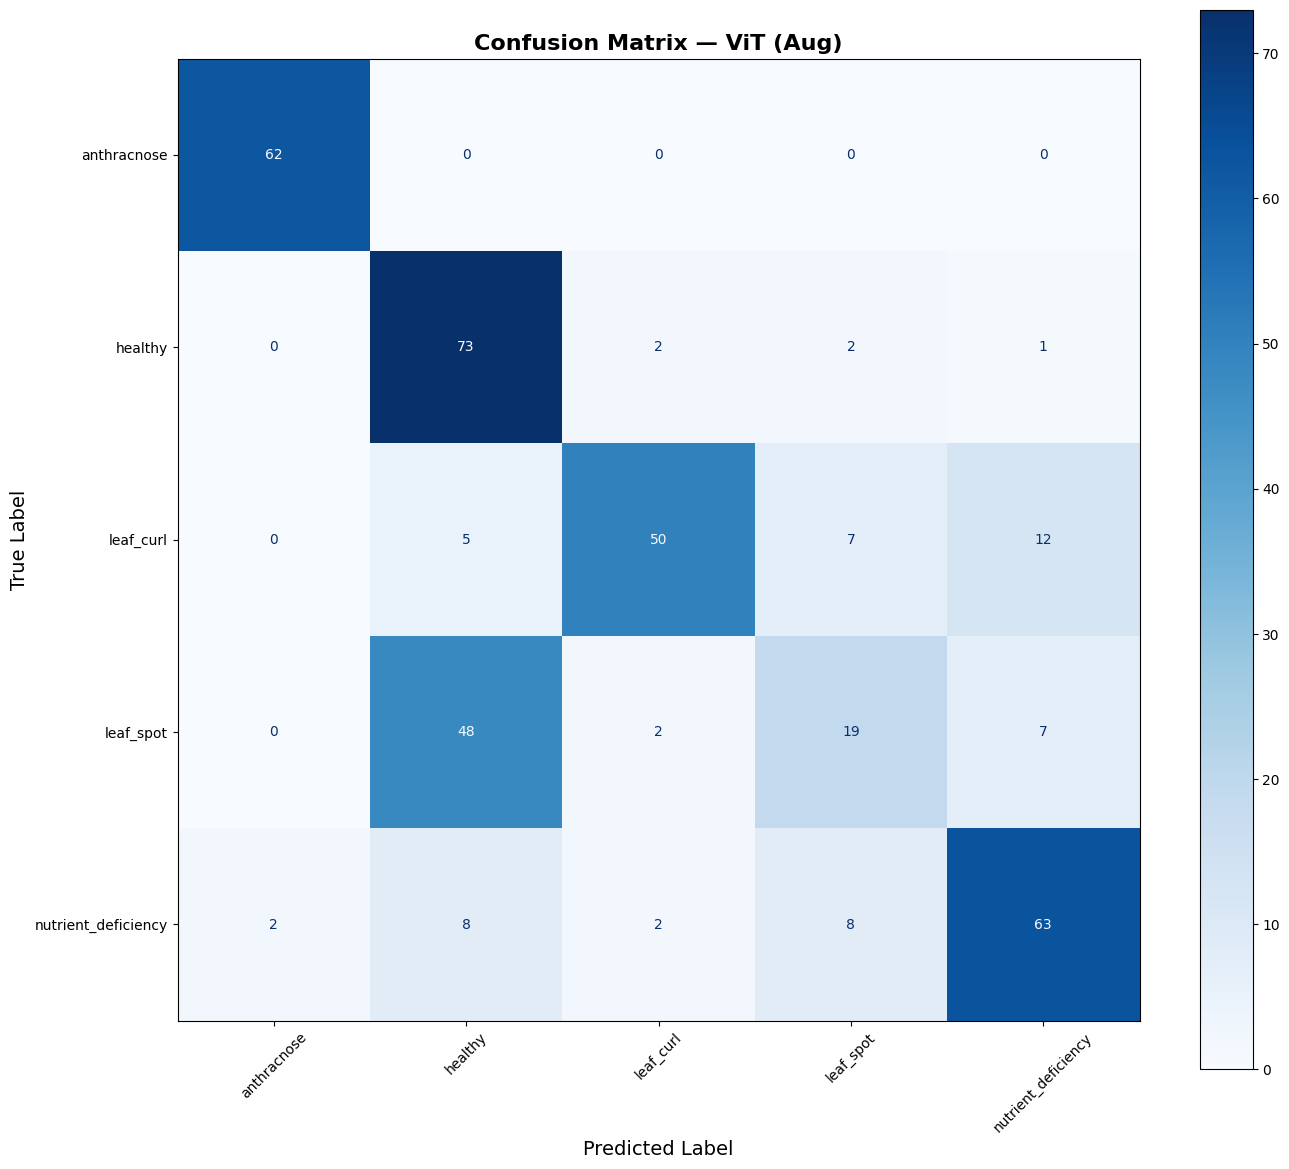

In [17]:
# BLOCK 15: Confusion Matrix — Scenario 2 (CELL RIÊNG BIỆT)
save_confusion_matrix(
    y_true_2, y_pred_2,
    title=f'Confusion Matrix — {MODEL_NAME} (Aug)',
    save_path=AUG_CONFUSION_MATRIX_PATH
)

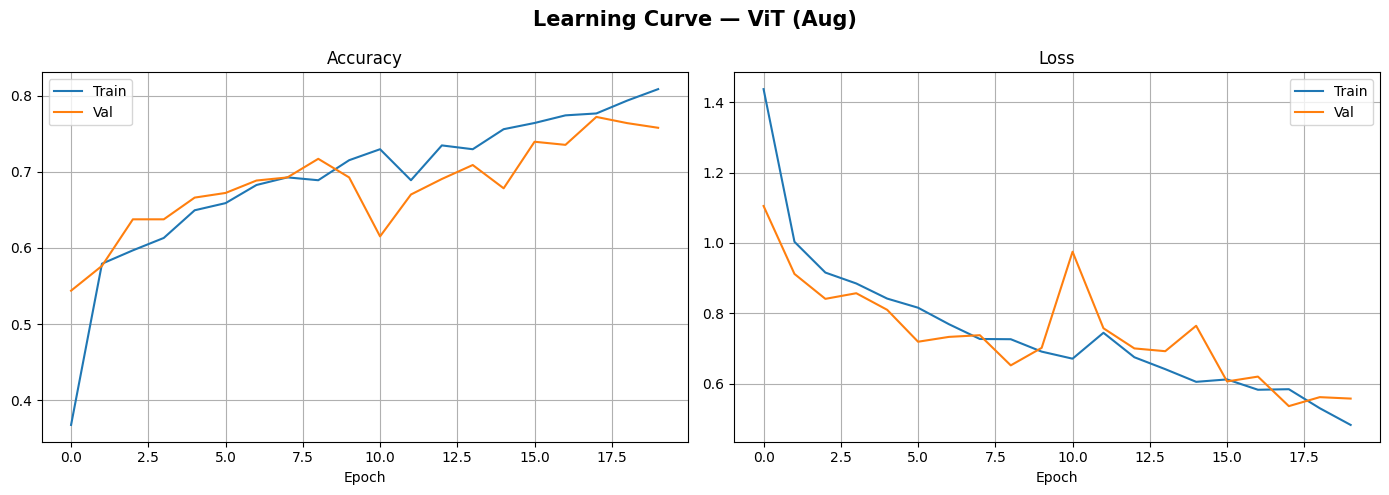

In [18]:
# BLOCK 16: Learning Curve — Scenario 2 (CELL RIÊNG BIỆT)
save_learning_curve(
    history_2,
    title=f'Learning Curve — {MODEL_NAME} (Aug)',
    save_path=AUG_LEARNING_CURVE_PATH
)

---
## EXCEL EXPORT

In [19]:
# BLOCK 17: Export results_summary.xlsx
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

EXCEL_OUTPUT_PATH = f'{OUTPUT_DIR}/results_summary.xlsx'

HEADERS    = ['STT', 'Tên Model', 'Accuracy', 'F1-score', 'Recall',
              'Learning Curve', 'Confusion Matrix', 'Parameters']
COL_WIDTHS = [6, 35, 12, 12, 12, 38, 38, 18]
IMG_ROW_HEIGHT = 200

def style_header_row(ws):
    fill   = PatternFill('solid', fgColor='1F4E79')
    font   = Font(bold=True, color='FFFFFF', size=11)
    border = Border(bottom=Side(style='medium', color='FFFFFF'),
                    right=Side(style='thin',   color='FFFFFF'))
    for col, header in enumerate(HEADERS, start=1):
        cell = ws.cell(row=1, column=col, value=header)
        cell.fill, cell.font, cell.border = fill, font, border
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)

def write_result_row(ws, row_num, stt, metrics, lc_path, cm_path):
    data = [
        stt,
        f"{metrics['model_name']} ({PAPER_CITATION})",
        round(metrics['accuracy'],     4),
        round(metrics['f1_macro'],     4),
        round(metrics['recall_macro'], 4),
        '', '',
        f"{metrics['total_params']:,}",
    ]
    for col, val in enumerate(data, start=1):
        cell = ws.cell(row=row_num, column=col, value=val)
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    ws.row_dimensions[row_num].height = IMG_ROW_HEIGHT
    if os.path.exists(lc_path):
        img = XLImage(lc_path); img.width, img.height = 280, 190
        ws.add_image(img, f'F{row_num}')
    if os.path.exists(cm_path):
        img = XLImage(cm_path); img.width, img.height = 280, 190
        ws.add_image(img, f'G{row_num}')

def build_sheet(wb, sheet_name, metrics, lc_path, cm_path):
    ws = wb.create_sheet(title=sheet_name)
    for col, width in enumerate(COL_WIDTHS, start=1):
        ws.column_dimensions[get_column_letter(col)].width = width
    ws.row_dimensions[1].height = 30
    style_header_row(ws)
    write_result_row(ws, 2, 1, metrics, lc_path, cm_path)
    return ws

wb = Workbook()
wb.remove(wb.active)
build_sheet(wb, 'Baseline',  baseline_metrics,
            BASELINE_LEARNING_CURVE_PATH, BASELINE_CONFUSION_MATRIX_PATH)
build_sheet(wb, 'Augmented', aug_metrics,
            AUG_LEARNING_CURVE_PATH, AUG_CONFUSION_MATRIX_PATH)
wb.save(EXCEL_OUTPUT_PATH)
print(f'[Excel] Saved: {EXCEL_OUTPUT_PATH}')
print(f'  Baseline  → Acc={baseline_metrics["accuracy"]:.4f} | F1={baseline_metrics["f1_macro"]:.4f} | Recall={baseline_metrics["recall_macro"]:.4f} | Params={baseline_metrics["total_params"]:,}')
print(f'  Augmented → Acc={aug_metrics["accuracy"]:.4f}      | F1={aug_metrics["f1_macro"]:.4f}      | Recall={aug_metrics["recall_macro"]:.4f}      | Params={aug_metrics["total_params"]:,}')

[Excel] Saved: /kaggle/working/results_summary.xlsx
  Baseline  → Acc=0.6917 | F1=0.7084 | Recall=0.7032 | Params=50,013,061
  Augmented → Acc=0.7158      | F1=0.7081      | Recall=0.7241      | Params=50,013,061
